# Task 1: Data Cleaning Project

**Dataset:** BigMart Sales (Kaggle)
**Objective:** Clean the raw dataset by handling missing values, duplicates, outliers, inconsistent labels and data types, then export an analysis-ready file.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Load and Explore the Raw Dataset

In [2]:
# Load the raw file (the notebook is in notebooks/, so go up one folder with ../)
raw = pd.read_csv("../data/raw/bigmart_train.csv")

# Work on a copy, so the raw data stays untouched
df = raw.copy()

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (8523, 12)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [3]:
# Shows each column's type and how many values are NOT missing
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   str    
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   str    
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   str    
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   str    
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   str    
 9   Outlet_Location_Type       8523 non-null   str    
 10  Outlet_Type                8523 non-null   str    
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


In [5]:
# Numeric columns: mean, spread, min, max, quartiles
display(df.describe())

# Text columns: how many distinct values, and the most common one
display(df.select_dtypes(exclude="number").describe())

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


,Item_Identifier,Item_Fat_Content,Item_Type,Outlet_Identifier,Outlet_Size,Outlet_Location_Type,Outlet_Type
count,8523,8523,8523,8523,6113,8523,8523
unique,1559,5,16,10,3,3,4
top,FDG33,Low Fat,Fruits and Vegetables,OUT027,Medium,Tier 3,Supermarket Type1
freq,10,5089,1232,935,2793,3350,5577


In [6]:
# These feed the before/after comparison table in the final report
before_metrics = {
    "Rows": df.shape[0],
    "Columns": df.shape[1],
    "Missing values": int(df.isnull().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
}
before_metrics

{'Rows': 8523, 'Columns': 12, 'Missing values': 3873, 'Duplicate rows': 0}

### Initial Observations
- The dataset has 8,523 rows and 12 columns, with no duplicate rows.
- Two columns have missing values: `Item_Weight` (1,463, 17.2%) and `Outlet_Size` (2,410, 28.3%).
- `Item_Fat_Content` has 5 distinct labels instead of 2, so the labels are inconsistent.
- `Item_Visibility` contains zeros, which are not valid for a product that is on sale.
- `Item_Outlet_Sales` is right-skewed (mean 2,181 vs median 1,794), and `Item_Visibility` has high values beyond the IQR limit, so outlier handling is needed.

## 2. Missing Value Analysis

In [35]:
### Missing Values

missing = pd.DataFrame({
    "missing_count": raw.isnull().sum(),
    "missing_pct": (raw.isnull().mean() * 100).round(2)
})
missing[missing["missing_count"] > 0]

,missing_count,missing_pct
Item_Weight,1463,17.17
Outlet_Size,2410,28.28


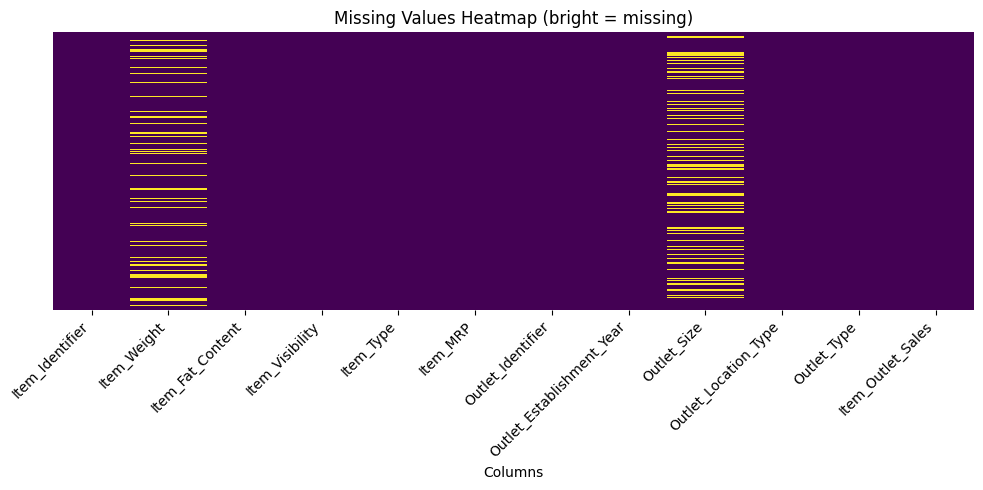

In [ ]:
plt.figure(figsize=(10, 5))
sns.heatmap(raw.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values Heatmap (bright = missing)")
plt.xlabel("Columns")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../outputs/charts/missing_values_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Are the missing Outlet_Size values tied to specific outlets?
print(raw[raw["Outlet_Size"].isnull()]["Outlet_Identifier"].value_counts())

# How many items never have a weight in any row?
no_weight = raw.groupby("Item_Identifier")["Item_Weight"].apply(lambda s: s.notnull().sum() == 0)
print("Items with no weight in any row:", no_weight.sum())

Outlet_Identifier
OUT045    929
OUT017    926
OUT010    555
Name: count, dtype: int64
Items with no weight in any row: 4


In [10]:
print(df["Item_Fat_Content"].value_counts())
print("Zero visibility rows:", (df["Item_Visibility"] == 0).sum())

Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64
Zero visibility rows: 526


### Missing Value Findings
- The heatmap shows gaps in only two columns: `Item_Weight` (1,463; 17.17%) and `Outlet_Size` (2,410; 28.28%).
- All missing `Outlet_Size` values belong to three outlets (OUT045, OUT017, OUT010), so the missingness is systematic: those outlets never recorded a size.
- Missing `Item_Weight` values are scattered, and only 4 items have no weight in any row.

In [11]:
# Known sizes by outlet type and location tier
known = df[df["Outlet_Size"].notnull()]
display(pd.crosstab([known["Outlet_Type"], known["Outlet_Location_Type"]], known["Outlet_Size"]))

# What type and tier do the 3 outlets with missing sizes have?
df[df["Outlet_Size"].isnull()][["Outlet_Identifier", "Outlet_Type", "Outlet_Location_Type"]].drop_duplicates()

Outlet_Size                             High  Medium  Small
Outlet_Type       Outlet_Location_Type                     
Grocery Store     Tier 1                   0       0    528
Supermarket Type1 Tier 1                   0     930    930
                  Tier 2                   0       0    930
                  Tier 3                 932       0      0
Supermarket Type2 Tier 3                   0     928      0
Supermarket Type3 Tier 3                   0     935      0

,Outlet_Identifier,Outlet_Type,Outlet_Location_Type
3,OUT010,Grocery Store,Tier 3
8,OUT045,Supermarket Type1,Tier 2
9,OUT017,Supermarket Type1,Tier 2


In [12]:
# Most common known size for each (outlet type, location tier) pair
size_lookup = known.groupby(["Outlet_Type", "Outlet_Location_Type"])["Outlet_Size"].agg(lambda s: s.mode().iloc[0])

overall_mode = df["Outlet_Size"].mode().iloc[0]    # fallback if a pair has no known size
missing_rows = df["Outlet_Size"].isnull()

df.loc[missing_rows, "Outlet_Size"] = df[missing_rows].apply(
    lambda r: size_lookup.get((r["Outlet_Type"], r["Outlet_Location_Type"]), overall_mode), axis=1)

print("Missing Outlet_Size:", df["Outlet_Size"].isnull().sum())

Missing Outlet_Size: 0


In [17]:
# OUT010 is a Grocery Store; the only known grocery store is Small, so use Small
df.loc[df["Outlet_Identifier"] == "OUT010", "Outlet_Size"] = "Small"

# Check: every Grocery Store should now be Small
pd.crosstab(df["Outlet_Type"], df["Outlet_Size"])

Outlet_Size,High,Medium,Small
Outlet_Type,,,
Grocery Store,0,0,1083
Supermarket Type1,932,930,3715
Supermarket Type2,0,928,0
Supermarket Type3,0,935,0


In [13]:
# Step A: reuse the weight the same item has in other rows
item_avg = df.groupby("Item_Identifier")["Item_Weight"].transform("mean")
df["Item_Weight"] = df["Item_Weight"].fillna(item_avg)

# Step B: the few items with no weight anywhere get the median of their item type
type_median = df.groupby("Item_Type")["Item_Weight"].transform("median")
df["Item_Weight"] = df["Item_Weight"].fillna(type_median)

print("Missing Item_Weight:", df["Item_Weight"].isnull().sum())

Missing Item_Weight: 0


In [14]:
df["Item_Fat_Content"] = df["Item_Fat_Content"].replace({"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular"})
print(df["Item_Fat_Content"].value_counts())

# Optional check: do non-consumable items (IDs starting with NC) carry a fat label?
print(df[df["Item_Identifier"].str.startswith("NC")]["Item_Fat_Content"].value_counts())

Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64
Item_Fat_Content
Low Fat    1599
Name: count, dtype: int64


In [18]:
print(df[df["Item_Identifier"].str.startswith("NC")]["Item_Type"].value_counts())

Item_Type
Household             910
Health and Hygiene    520
Others                169
Name: count, dtype: int64


In [19]:
df.loc[df["Item_Identifier"].str.startswith("NC"), "Item_Fat_Content"] = "Non-Edible"
print(df["Item_Fat_Content"].value_counts())

Item_Fat_Content
Low Fat       3918
Regular       3006
Non-Edible    1599
Name: count, dtype: int64


In [15]:
df["Item_Visibility"] = df["Item_Visibility"].replace(0, np.nan)

item_vis = df.groupby("Item_Identifier")["Item_Visibility"].transform("mean")
df["Item_Visibility"] = df["Item_Visibility"].fillna(item_vis).fillna(df["Item_Visibility"].median())

print("Zero or missing visibility:", ((df["Item_Visibility"] == 0) | df["Item_Visibility"].isnull()).sum())

Zero or missing visibility: 0


In [16]:
print("Total missing values now:", df.isnull().sum().sum())

Total missing values now: 0


### Missing Value and Label Decisions
- **Item_Weight (1,463 missing):** filled with the same item's weight from its other rows, since an item's weight does not change. The 4 items with no weight anywhere were filled with the median weight of their item type.
- **Outlet_Size (2,410 missing):** all gaps belonged to three outlets (OUT045, OUT017, OUT010). They were filled using the known size of outlets with the same type and location tier. OUT010 is a Tier 3 grocery store with no matching group, so it was set to `Small`, the size of the only other grocery store.
- **Item_Fat_Content:** `LF` and `low fat` were mapped to `Low Fat`, and `reg` to `Regular`. The 1,599 non-consumable items (IDs starting `NC`: household, health and hygiene, others) were relabelled `Non-Edible`, because a fat label is meaningless for them.
- **Item_Visibility (526 zeros):** a product on sale cannot have zero visibility, so the zeros were treated as missing and filled with that item's average visibility.

## 3. Duplicate Records

In [20]:
print("Fully duplicated rows:", df.duplicated().sum())

# The same item should appear only once in each outlet
print("Repeated item-outlet pairs:", df.duplicated(subset=["Item_Identifier", "Outlet_Identifier"]).sum())

df = df.drop_duplicates()    # removes nothing if both counts are 0
print("Rows after duplicate check:", df.shape[0])

Fully duplicated rows: 0
Repeated item-outlet pairs: 0
Rows after duplicate check: 8523


In [ ]:
## 4. Outlier Detection (IQR Method)

In [21]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

num_cols = ["Item_Weight", "Item_Visibility", "Item_MRP", "Item_Outlet_Sales"]

rows = []
for c in num_cols:
    low, high = iqr_bounds(df[c])
    n = int(((df[c] < low) | (df[c] > high)).sum())
    rows.append({"column": c, "lower_bound": round(low, 3), "upper_bound": round(high, 3),
                 "outliers": n, "outlier_pct": round(n / len(df) * 100, 2)})

outlier_table = pd.DataFrame(rows)
outlier_table

,column,lower_bound,upper_bound,outliers,outlier_pct
0,Item_Weight,-3.313,28.948,0,0.00
1,Item_Visibility,-0.070,0.200,144,1.69
2,Item_MRP,-43.899,323.370,0,0.00
3,Item_Outlet_Sales,-2566.326,6501.870,186,2.18


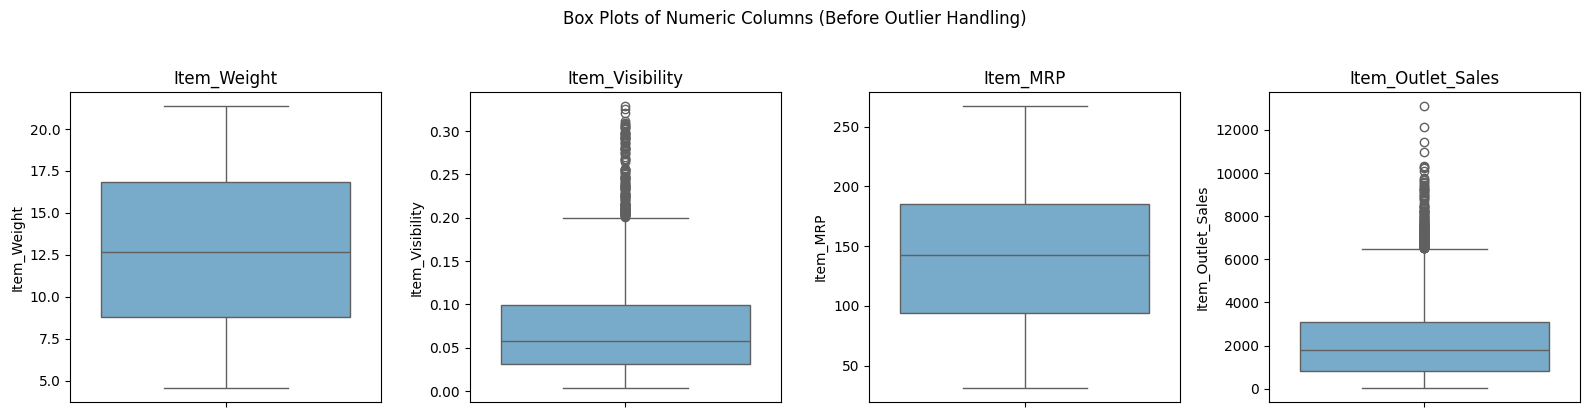

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#6baed6")
    ax.set_title(c)
plt.suptitle("Box Plots of Numeric Columns (Before Outlier Handling)", y=1.03)
plt.tight_layout()
plt.savefig("../outputs/charts/outlier_boxplots_before.png", dpi=300, bbox_inches="tight")
plt.show()

### Outlier Handling Decision
- `Item_Weight` and `Item_MRP` have no outliers by the IQR rule.
- `Item_Visibility`: 144 values (1.69%) exceed the upper bound of 0.200. They were **capped** at 0.200, which keeps every row but limits their influence.
- `Item_Outlet_Sales`: 186 values (2.18%) exceed 6,501.87. They are plausible sales of popular items, and this is the column to be predicted, so they were **kept and flagged** in `sales_outlier_flag` and not removed.

In [23]:
### cap visibility
low, high = iqr_bounds(df["Item_Visibility"])
n_capped = int((df["Item_Visibility"] > high).sum())

df["Item_Visibility"] = df["Item_Visibility"].clip(upper=high)    # values above the bound become the bound
print("Values capped:", n_capped, "| new maximum:", round(df["Item_Visibility"].max(), 3))

Values capped: 144 | new maximum: 0.2


In [24]:
###flag the high sales, and check they are plausible

low_s, high_s = iqr_bounds(df["Item_Outlet_Sales"])
df["sales_outlier_flag"] = df["Item_Outlet_Sales"] > high_s
print("Flagged high-sales rows:", df["sales_outlier_flag"].sum())

# Where do they come from? If they sit mostly in the larger outlets, they are real, not errors
df[df["sales_outlier_flag"]].groupby("Outlet_Type")["Item_Outlet_Sales"].agg(["count", "mean"]).round(0)

Flagged high-sales rows: 186


,count,mean
Outlet_Type,,
Supermarket Type1,80,7371.0
Supermarket Type2,3,6703.0
Supermarket Type3,103,7888.0


The 186 flagged high-sales rows come only from supermarkets (Type 3 has 103 of them, averaging about 7,888), and none from grocery stores. This pattern suggests they are genuine sales from larger outlets and not data errors, which supports keeping them.

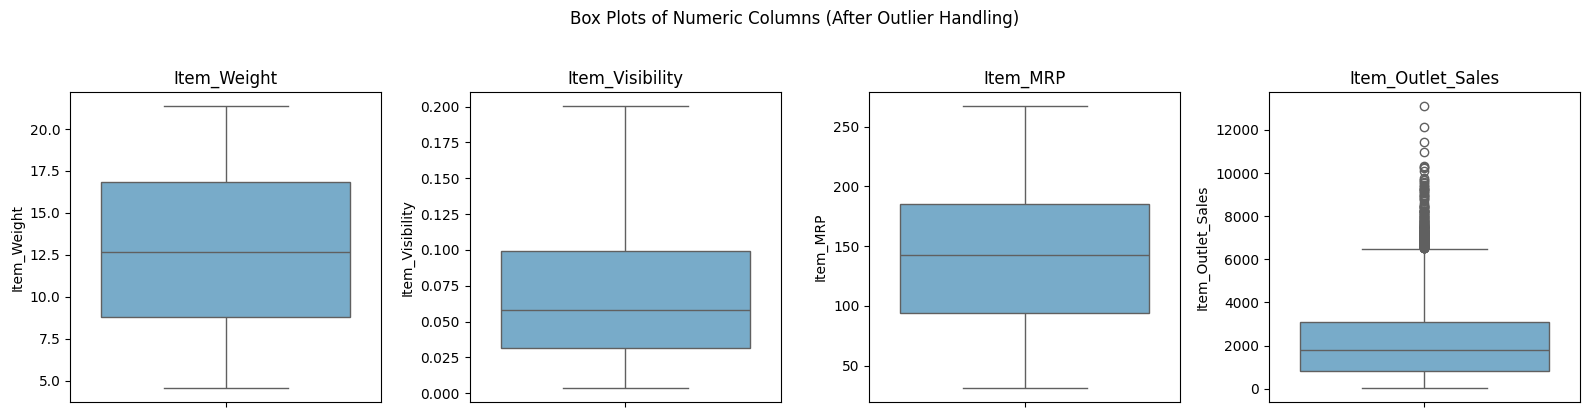

In [25]:
###the box plot after handling

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#6baed6")
    ax.set_title(c)
plt.suptitle("Box Plots of Numeric Columns (After Outlier Handling)", y=1.03)
plt.tight_layout()
plt.savefig("../outputs/charts/outlier_boxplots_after.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Column Names and Data Types

In [26]:
# 1) snake_case column names
df.columns = df.columns.str.lower()
print(df.columns.tolist())

# 2) Categorical columns get the 'category' type
cat_cols = ["item_fat_content", "item_type", "outlet_identifier", "outlet_size",
            "outlet_location_type", "outlet_type"]
df[cat_cols] = df[cat_cols].astype("category")

df.dtypes

['item_identifier', 'item_weight', 'item_fat_content', 'item_visibility', 'item_type', 'item_mrp', 'outlet_identifier', 'outlet_establishment_year', 'outlet_size', 'outlet_location_type', 'outlet_type', 'item_outlet_sales', 'sales_outlier_flag']


item_identifier                   str
item_weight                   float64
item_fat_content             category
item_visibility               float64
item_type                    category
item_mrp                      float64
outlet_identifier            category
outlet_establishment_year       int64
outlet_size                  category
outlet_location_type         category
outlet_type                  category
item_outlet_sales             float64
sales_outlier_flag               bool
dtype: object

## 6. Encoding Categorical Variables
- **Ordinal encoding** for categories with a natural order: `outlet_size` (Small < Medium < High) and `outlet_location_type` (Tier 1 < Tier 2 < Tier 3).
- **One-hot encoding** for categories with no order: `item_fat_content`, `item_type` and `outlet_type`.
- `item_identifier` (1,559 unique values) and `outlet_identifier` are dropped from the encoded file, because they are labels and not features.
- `sales_outlier_flag` is dropped from the encoded file, because it is derived from the target (sales) and would leak the answer into a model.

In [27]:
# Keep the readable version (text categories) for EDA in Task 2
df_clean = df.copy()

# Ordinal encoding
size_map = {"Small": 0, "Medium": 1, "High": 2}
tier_map = {"Tier 1": 0, "Tier 2": 1, "Tier 3": 2}

df_enc = df.copy()
df_enc["outlet_size"] = df_enc["outlet_size"].astype(str).map(size_map).astype(int)
df_enc["outlet_location_type"] = df_enc["outlet_location_type"].astype(str).map(tier_map).astype(int)

# One-hot encoding (drop_first avoids one redundant column per category)
df_enc = pd.get_dummies(df_enc, columns=["item_fat_content", "item_type", "outlet_type"],
                        drop_first=True, dtype=int)

# Drop identifiers and the target-derived flag
df_enc = df_enc.drop(columns=["item_identifier", "outlet_identifier", "sales_outlier_flag"])

print("Encoded shape:", df_enc.shape)
df_enc.head()

Encoded shape: (8523, 27)


,item_weight,item_visibility,item_mrp,outlet_establishment_year,outlet_size,outlet_location_type,item_outlet_sales,item_fat_content_Non-Edible,item_fat_content_Regular,item_type_Breads,item_type_Breakfast,item_type_Canned,item_type_Dairy,item_type_Frozen Foods,item_type_Fruits and Vegetables,item_type_Hard Drinks,item_type_Health and Hygiene,item_type_Household,item_type_Meat,item_type_Others,item_type_Seafood,item_type_Snack Foods,item_type_Soft Drinks,item_type_Starchy Foods,outlet_type_Supermarket Type1,outlet_type_Supermarket Type2,outlet_type_Supermarket Type3
0,9.30,0.016047,249.8092,1999,1,0,3735.1380,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,5.92,0.019278,48.2692,2009,1,2,443.4228,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0
2,17.50,0.016760,141.6180,1999,1,0,2097.2700,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0
3,19.20,0.022911,182.0950,1998,0,2,732.3800,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
4,8.93,0.016164,53.8614,1987,2,2,994.7052,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0


In [ ]:
## 7. Validation of the Cleaned Dataset

In [28]:
print("Missing values (readable):", df_clean.isnull().sum().sum())
print("Missing values (encoded):", df_enc.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())
print("Non-numeric columns in encoded file:", df_enc.select_dtypes(exclude="number").columns.tolist())

display(df_clean.describe())
df_clean["item_fat_content"].value_counts()

Missing values (readable): 0
Missing values (encoded): 0
Duplicate rows: 0
Non-numeric columns in encoded file: []


,item_weight,item_visibility,item_mrp,outlet_establishment_year,item_outlet_sales
count,8523.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.875361,0.069983,140.992782,1997.831867,2181.288914
std,4.645031,0.047720,62.275067,8.371760,1706.499616
min,4.555000,0.003575,31.290000,1985.000000,33.290000
25%,8.785000,0.031395,93.826500,1987.000000,834.247400
50%,12.650000,0.058100,143.012800,1999.000000,1794.331000
75%,16.850000,0.098867,185.643700,2004.000000,3101.296400
max,21.350000,0.200075,266.888400,2009.000000,13086.964800


item_fat_content
Low Fat       3918
Regular       3006
Non-Edible    1599
Name: count, dtype: int64

In [31]:
low_raw, high_raw = iqr_bounds(raw["Item_Visibility"])
raw_vis_outliers = int(((raw["Item_Visibility"] < low_raw) | (raw["Item_Visibility"] > high_raw)).sum())
print("Visibility outliers in the raw data:", raw_vis_outliers)

Visibility outliers in the raw data: 144


In [32]:
vis_low, vis_high = iqr_bounds(df_clean["item_visibility"])

comparison = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Total missing values", "Duplicate rows",
               "Fat content labels", "Zero visibility values",
               "Visibility outliers (IQR)", "Sales outliers (IQR)"],
    "Before": [before_metrics["Rows"], before_metrics["Columns"], before_metrics["Missing values"],
               before_metrics["Duplicate rows"], 5, 526, raw_vis_outliers, 186],
    "After": [df_clean.shape[0], df_clean.shape[1], int(df_clean.isnull().sum().sum()),
              int(df_clean.duplicated().sum()), df_clean["item_fat_content"].nunique(),
              int((df_clean["item_visibility"] == 0).sum()),
              int((df_clean["item_visibility"] > vis_high).sum()),
              "186 (kept, flagged)"],
})
comparison

,Metric,Before,After
0,Rows,8523,8523
1,Columns,12,13
2,Total missing values,3873,0
3,Duplicate rows,0,0
4,Fat content labels,5,3
5,Zero visibility values,526,0
6,Visibility outliers (IQR),144,0
7,Sales outliers (IQR),186,"186 (kept, flagged)"


## 8. Export
The cleaned dataset is saved in two versions: a readable one for exploratory analysis (Task 2), and an encoded one for modelling.

In [30]:
df_clean.to_csv("../data/cleaned/bigmart_cleaned.csv", index=False)
df_enc.to_csv("../data/cleaned/bigmart_cleaned_encoded.csv", index=False)

import os
print(os.listdir("../data/cleaned"))

['bigmart_cleaned.csv', 'bigmart_cleaned_encoded.csv']
